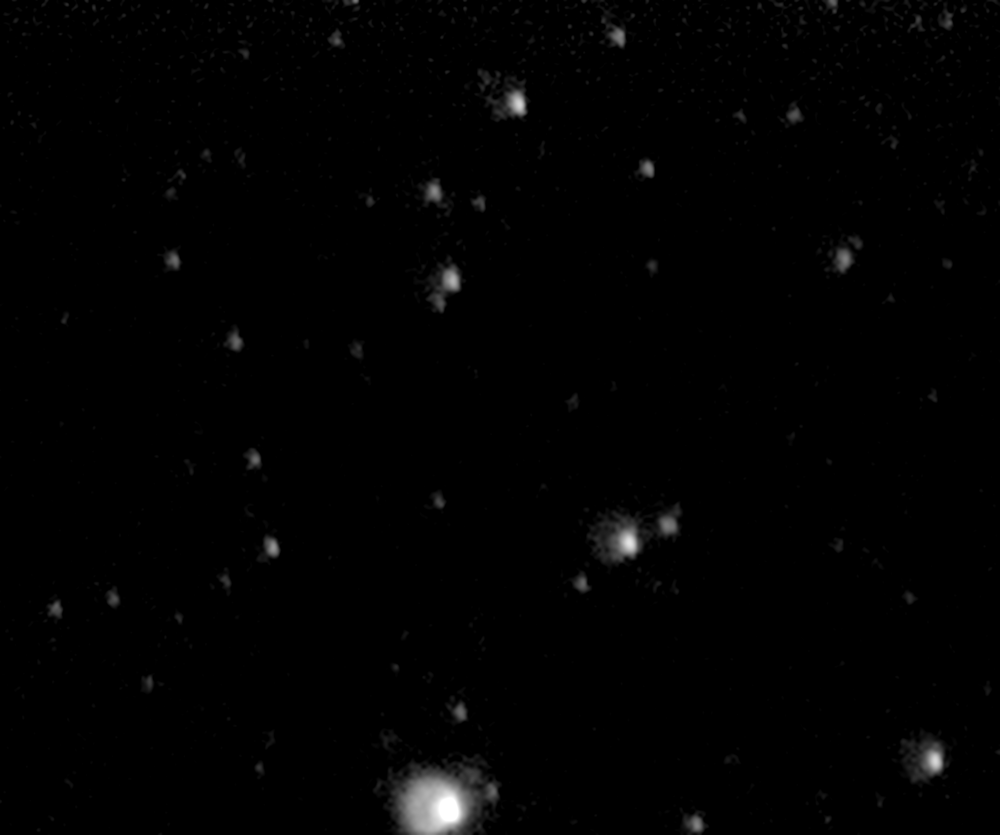

In [13]:
import numpy as np
from astropy.io import fits
from astropy.stats import SigmaClip, sigma_clipped_stats
from astropy.visualization import ManualInterval, AsinhStretch, ImageNormalize
from photutils.background import Background2D, MedianBackground
from scipy.ndimage import gaussian_filter, zoom
import matplotlib.pyplot as plt
from IPython.display import Image, display

# 1. Load deepest stack (N=71) and crop the noisy drift borders
raw = fits.getdata("out/stack_0071.fits").astype(np.float32)
data = raw[:224, 52:]

# 2. Subtract uneven sky glow cleanly
bkg = Background2D(data, box_size=(32, 32), filter_size=(3, 3),
                   sigma_clip=SigmaClip(sigma=3.0), bkg_estimator=MedianBackground())
sub = data - bkg.background

# 3. Upscale 3x with bicubic spline interpolation to eliminate pixel blockiness
upscaled = zoom(sub, zoom=3.0, order=3)

# 4. Apply subtle deconvolution/unsharp mask to tighten star cores into crisp pinpoints
blurred = gaussian_filter(upscaled, sigma=2.2)
sharpened = upscaled + 0.45 * (upscaled - blurred)
final_sky = gaussian_filter(sharpened, sigma=0.7)

# 6. Render clean, unobstructed 300 DPI night sky image (no circles or text)
fig, ax = plt.subplots(figsize=(10, 8.4), dpi=300)
fig.patch.set_facecolor("black")
ax.set_facecolor("black")

ax.imshow(final_sky, origin="lower", cmap="gray", norm=norm, interpolation="lanczos")
ax.axis("off")

plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.savefig("out/night_sky_clean_hires.png", facecolor="black", dpi=300, bbox_inches="tight", pad_inches=0)
plt.close()

display(Image(filename="out/night_sky_clean_hires.png"))


Aligned 60 valid sharp frames out of 100 total.
Processing 5-frame stack...


C:\Users\aizah\AppData\Local\Temp\ipykernel_22980\2139887224.py:80: RuntimeWarning: Mean of empty slice
  clean_stack = np.nanmean(clipped, axis=0)


Saved: out_run2_sharp/night_sky_deconvolved_05frames.png


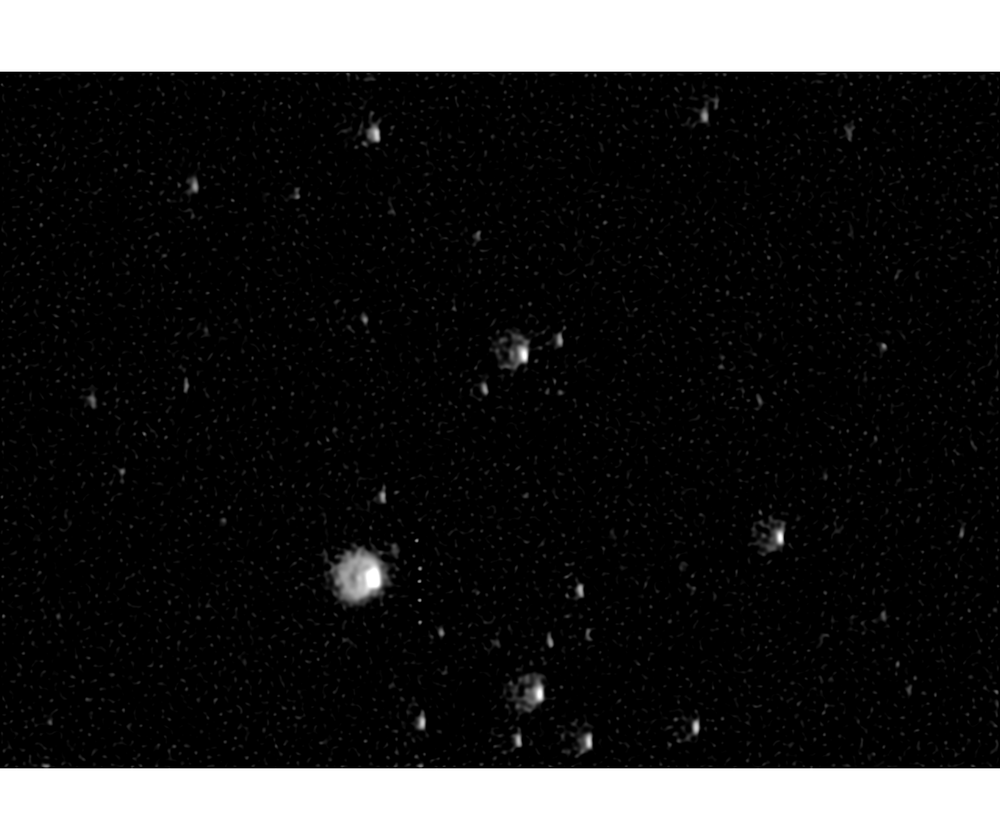

Processing 10-frame stack...


C:\Users\aizah\AppData\Local\Temp\ipykernel_22980\2139887224.py:80: RuntimeWarning: Mean of empty slice
  clean_stack = np.nanmean(clipped, axis=0)


Saved: out_run2_sharp/night_sky_deconvolved_10frames.png


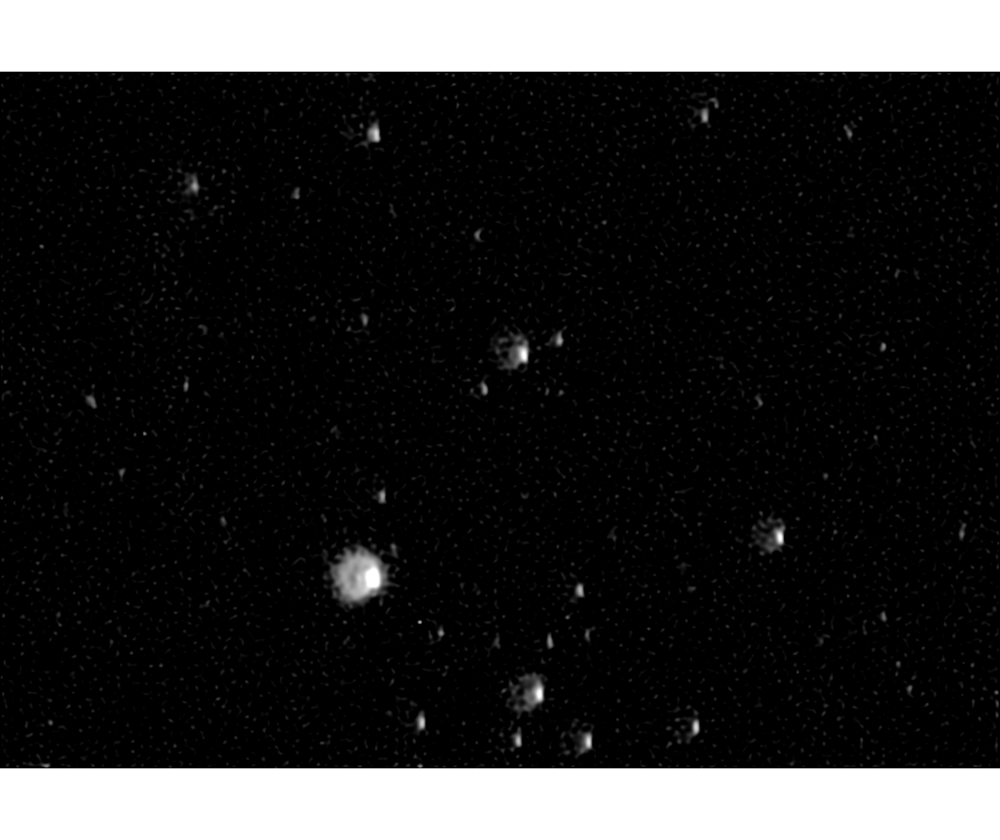

Processing 20-frame stack...
Saved: out_run2_sharp/night_sky_deconvolved_20frames.png


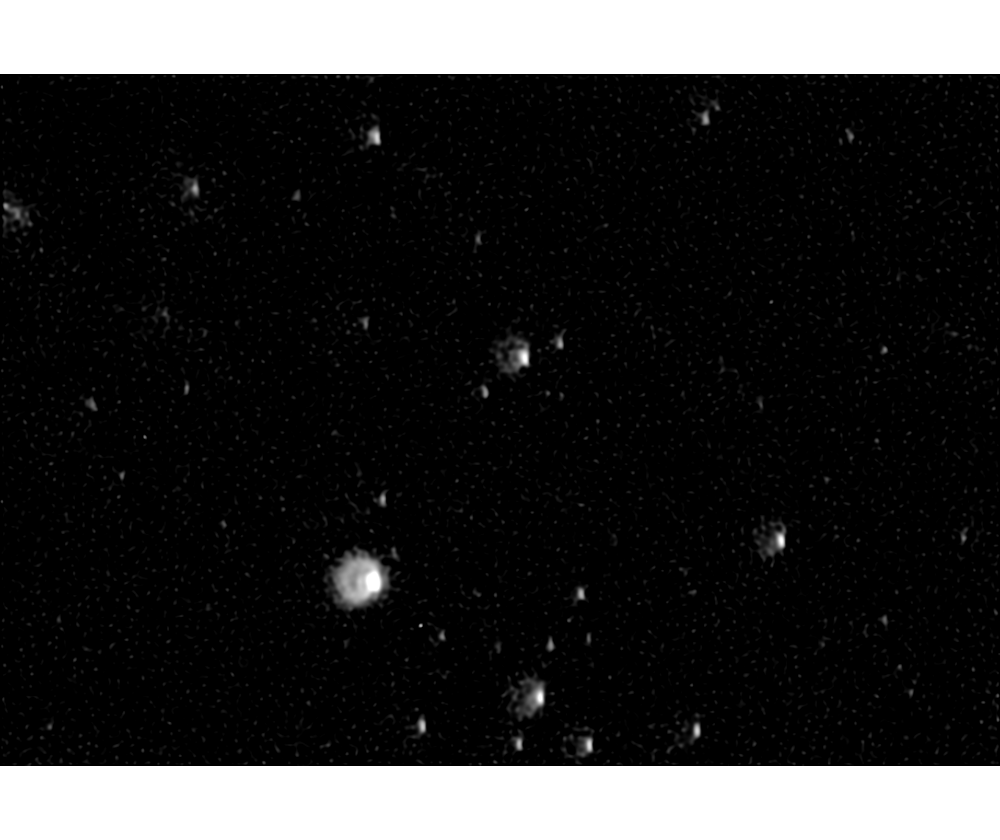

Processing 30-frame stack...
Saved: out_run2_sharp/night_sky_deconvolved_30frames.png


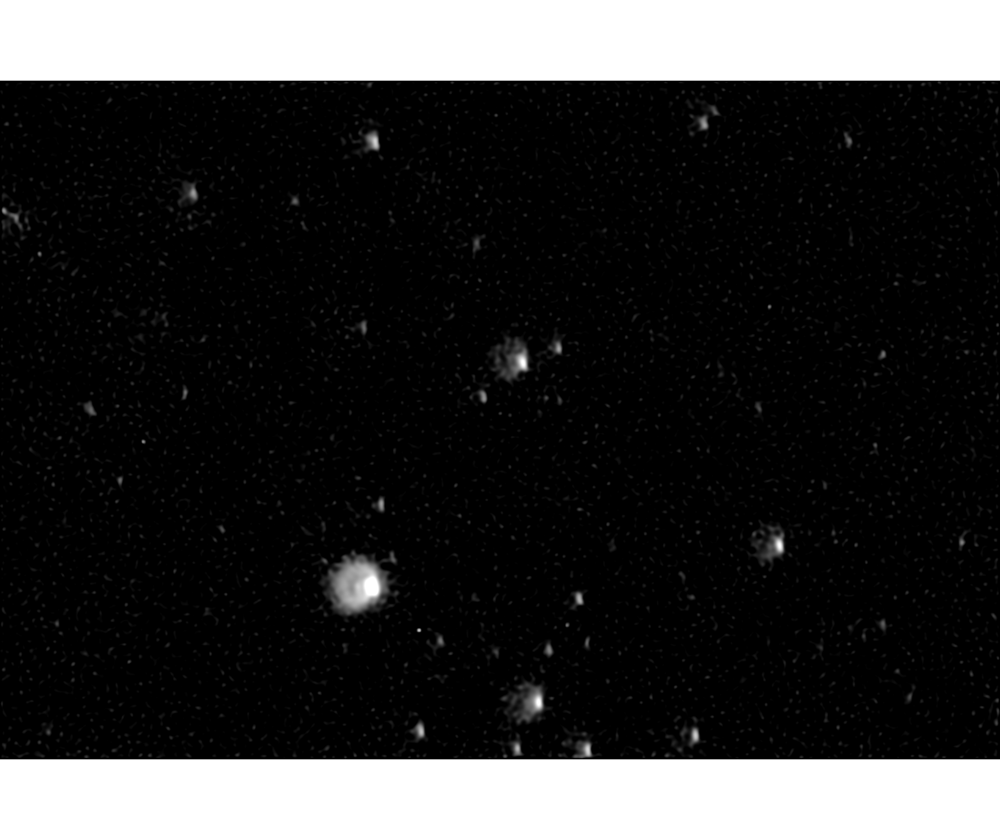

Processing 40-frame stack...
Saved: out_run2_sharp/night_sky_deconvolved_40frames.png


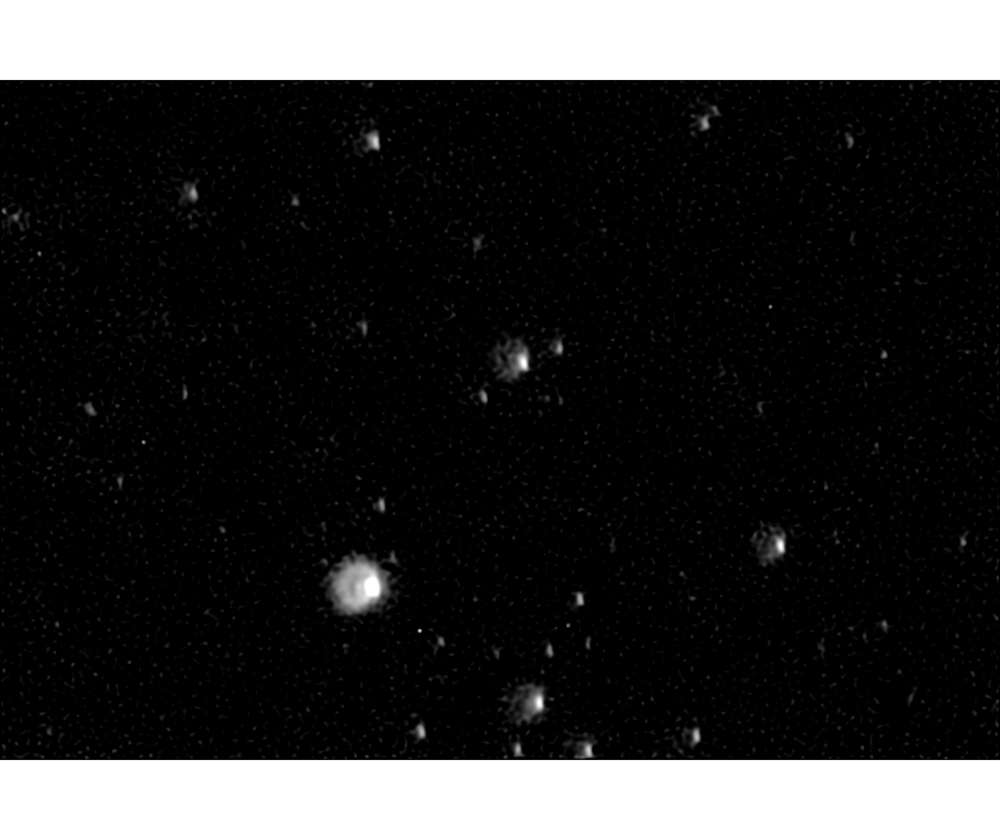

Processing 50-frame stack...
Saved: out_run2_sharp/night_sky_deconvolved_50frames.png


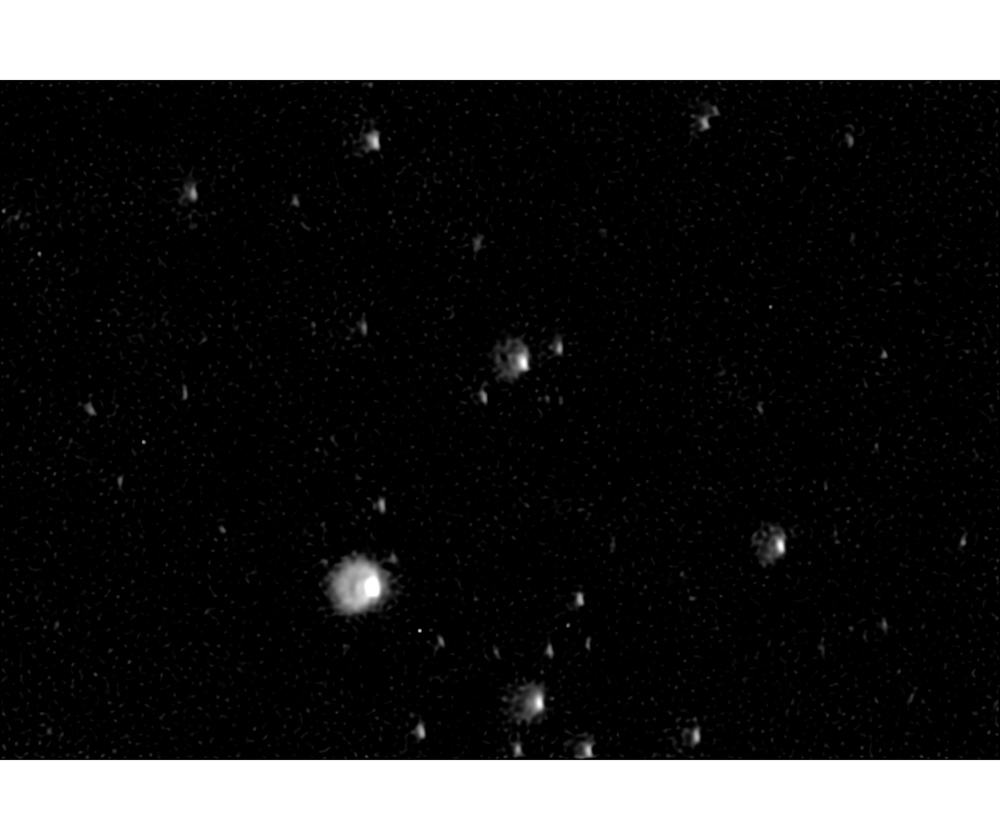

Processing 60-frame stack...
Saved: out_run2_sharp/night_sky_deconvolved_60frames.png


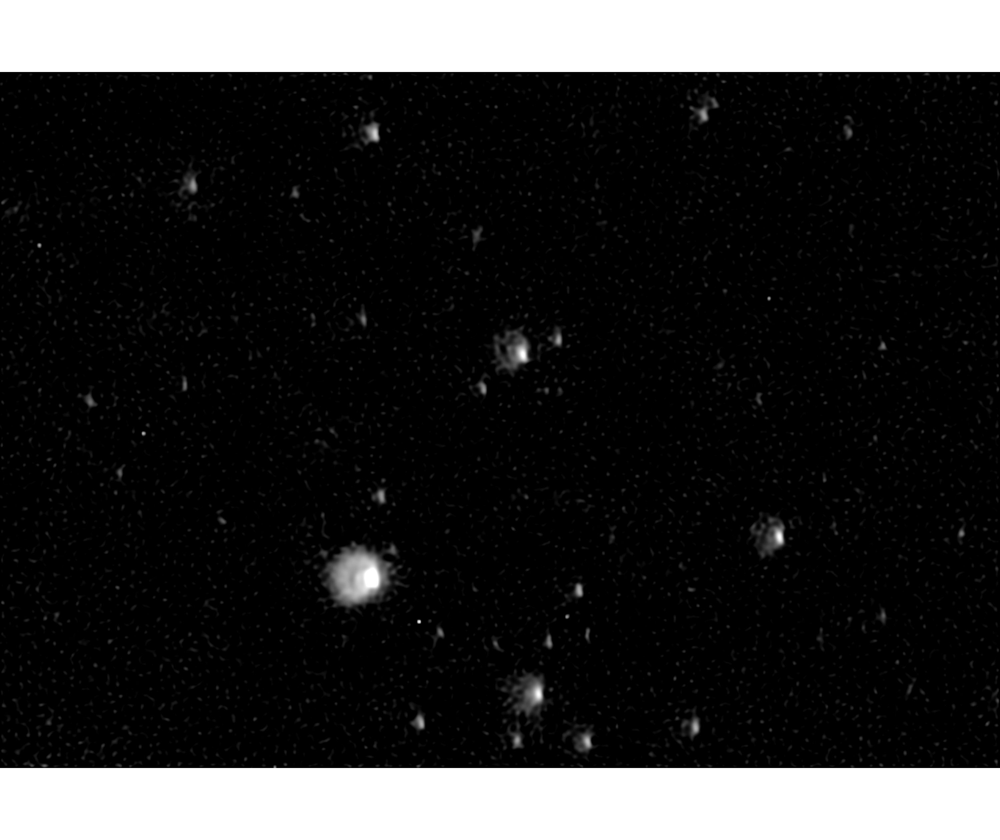

In [6]:
import os
import struct
import numpy as np
from astropy.io import fits
from astropy.stats import SigmaClip, sigma_clipped_stats
from astropy.visualization import ManualInterval, AsinhStretch, ImageNormalize
from photutils.background import Background2D, MedianBackground
from skimage.registration import phase_cross_correlation
from skimage.restoration import richardson_lucy
from scipy.ndimage import shift as nd_shift, gaussian_filter, zoom
import matplotlib.pyplot as plt
from IPython.display import Image, display

# 1. Load all frames from your .ser video
ser_file = r"C:\Users\aizah\Star\111126\2026-11-11-0521_6-G-Star.ser"
out_dir = "out_run2_sharp"
os.makedirs(out_dir, exist_ok=True)

with open(ser_file, "rb") as f:
    header = f.read(178)
    _, _, _, _, width, height, depth, frame_count = struct.unpack("<14sIIIIIII", header[:42])
    dtype = np.uint16 if depth > 8 else np.uint8
    raw_data = np.fromfile(f, dtype=dtype, count=width * height * frame_count)
    frames = raw_data.reshape((-1, height, width)).astype(np.float32)

# 2. LUCKY IMAGING: Score every frame by sharpness
def sharpness_score(img):
    hp = img - gaussian_filter(img, 5.0)
    return float(np.percentile(hp, 99.9) / (np.std(hp) + 1e-5))

scores = [sharpness_score(fr) for fr in frames]
sorted_idx = np.argsort(scores)[::-1]

# 3. Sub-pixel align the sharpest frames up to the max stack size (60)
# Aligning a larger buffer (e.g. top 75) ensures we still get 60 valid frames if a few jump > 120 px
stack_counts = [5, 10, 20, 30, 40, 50, 60]
max_needed = max(stack_counts)

ref = frames[sorted_idx[0]]
ref_hp = gaussian_filter(ref - gaussian_filter(ref, 10.0), 1.0)

aligned_cube = []
for idx in sorted_idx:
    if len(aligned_cube) >= max_needed:
        break
    fr = frames[idx]
    fr_hp = gaussian_filter(fr - gaussian_filter(fr, 10.0), 1.0)
    shift_yx, error, _ = phase_cross_correlation(ref_hp, fr_hp, upsample_factor=10)
    
    # Skip frames with wild jumps (> 120 px)
    if np.hypot(*shift_yx) > 120:
        continue
        
    moved = nd_shift(fr, shift=shift_yx, order=3, mode="constant", cval=np.nan)
    aligned_cube.append(moved)

full_aligned_cube = np.array(aligned_cube)
print(f"Aligned {len(full_aligned_cube)} valid sharp frames out of {len(frames)} total.")

# Precompute PSF for Richardson-Lucy Deconvolution
psf_size = 15
y, x = np.mgrid[-psf_size//2 + 1:psf_size//2 + 1, -psf_size//2 + 1:psf_size//2 + 1]
psf_sigma = 1.6  # Matches ~3.8 px star FWHM; increase to 1.9 if stars are still soft
psf = np.exp(-(x**2 + y**2) / (2.0 * psf_sigma**2))
psf /= psf.sum()

# 4. Generate stacks for each requested frame count
for n_frames in stack_counts:
    if len(full_aligned_cube) < n_frames:
        print(f"Skipping {n_frames}-frame stack (only {len(full_aligned_cube)} valid frames available).")
        continue
        
    print(f"Processing {n_frames}-frame stack...")
    stack_cube = full_aligned_cube[:n_frames]

    # Sigma-clipped mean stack
    mean_est = np.nanmean(stack_cube, axis=0)
    std_est = np.nanstd(stack_cube, axis=0)
    clipped = np.where(np.abs(stack_cube - mean_est) < 2.2 * std_est, stack_cube, np.nan)
    clean_stack = np.nanmean(clipped, axis=0)

    # Auto-crop drift edges where fewer than 70% of frames overlapped
    coverage = np.mean(np.isfinite(stack_cube), axis=0)
    valid_rows = np.mean(coverage > 0.7, axis=1) > 0.8
    valid_cols = np.mean(coverage > 0.7, axis=0) > 0.8
    cropped = np.nan_to_num(clean_stack[np.ix_(valid_rows, valid_cols)], nan=np.nanmedian(clean_stack))

    # Subtract sky background cleanly
    bkg = Background2D(
        cropped, 
        box_size=(32, 32), 
        filter_size=(3, 3), 
        sigma_clip=SigmaClip(sigma=3.0), 
        bkg_estimator=MedianBackground()
    )
    sub = np.clip(cropped - bkg.background, 0, None)

    # Richardson-Lucy Deconvolution
    max_val = sub.max()
    deconvolved = richardson_lucy(sub / max_val, psf, num_iter=12, clip=False) * max_val

    # Optional: Save FITS for each stack count
    # fits.PrimaryHDU(deconvolved.astype(np.float32)).writeto(f"{out_dir}/sharp_deconvolved_{n_frames}f.fits", overwrite=True)

    # Upscale 3x and render pure, crisp black-and-white night sky image
    upscaled = zoom(deconvolved, zoom=3.0, order=3)
    _, median, std = sigma_clipped_stats(upscaled, sigma=3.0)
    vmin = median + 1.5 * std
    vmax = np.percentile(upscaled, 99.97)
    norm = ImageNormalize(upscaled, interval=ManualInterval(vmin=vmin, vmax=vmax), stretch=AsinhStretch(a=0.03))

    fig, ax = plt.subplots(figsize=(10, 8.4), dpi=300)
    ax.imshow(upscaled, cmap="gray", norm=norm, origin="lower")
    ax.axis("off")
    
    out_png = f"{out_dir}/night_sky_deconvolved_{n_frames:02d}frames.png"
    plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
    plt.savefig(out_png, dpi=300, pad_inches=0)
    plt.close(fig)
    
    print(f"Saved: {out_png}")
    display(Image(filename=out_png))


Found 100 light frames.
No darks found -> skipping dark subtraction.

--- Reached 1 stacked frames ---
Saved & rendered: output/night_sky_01frames.png (cropped shape: (480, 640))


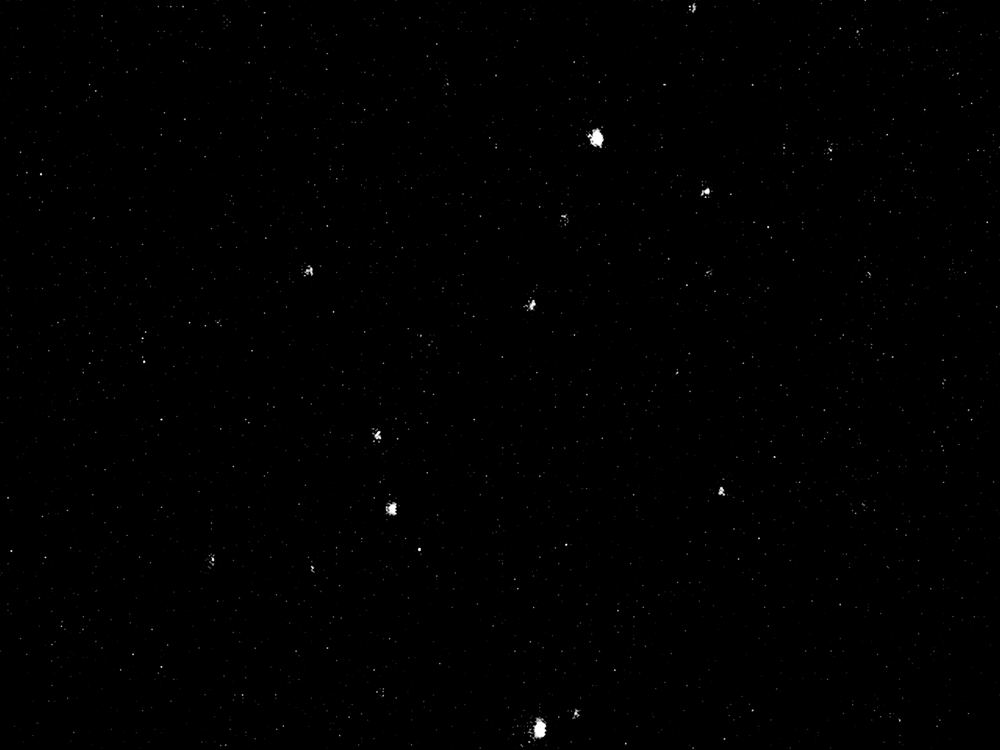


--- Reached 5 stacked frames ---
Saved & rendered: output/night_sky_05frames.png (cropped shape: (460, 639))


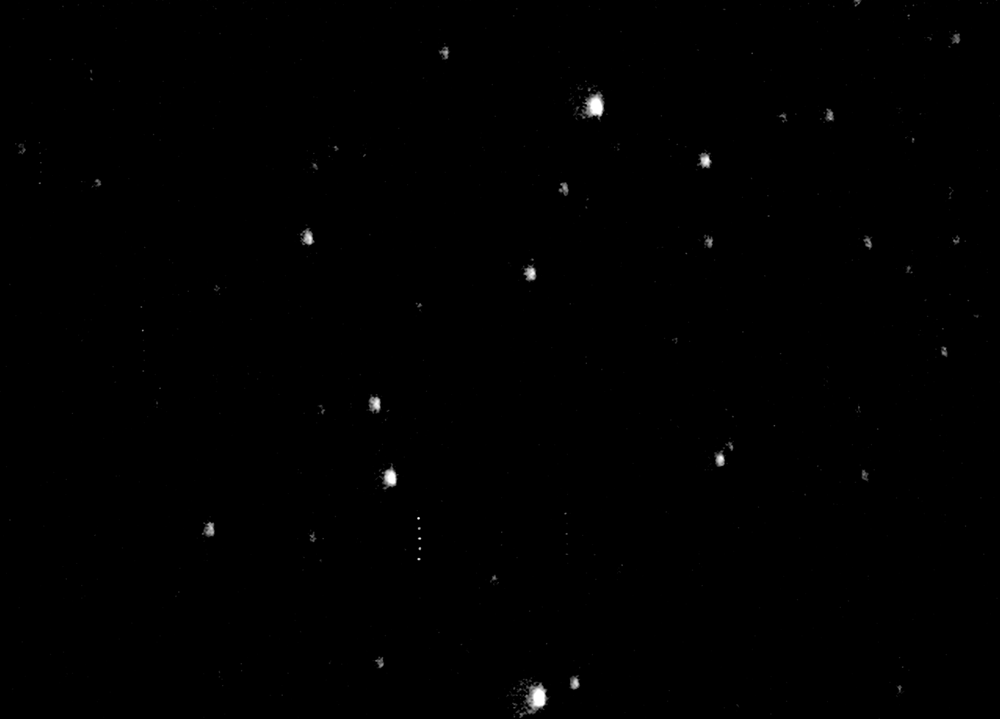


--- Reached 10 stacked frames ---
Saved & rendered: output/night_sky_10frames.png (cropped shape: (441, 638))


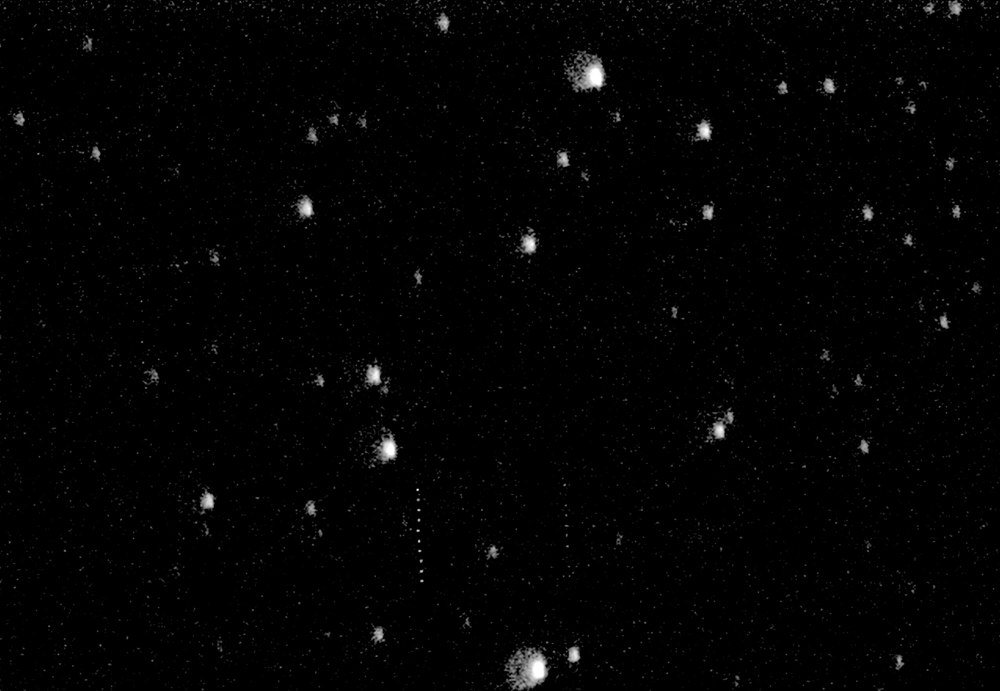


--- Reached 20 stacked frames ---
Saved & rendered: output/night_sky_20frames.png (cropped shape: (395, 636))


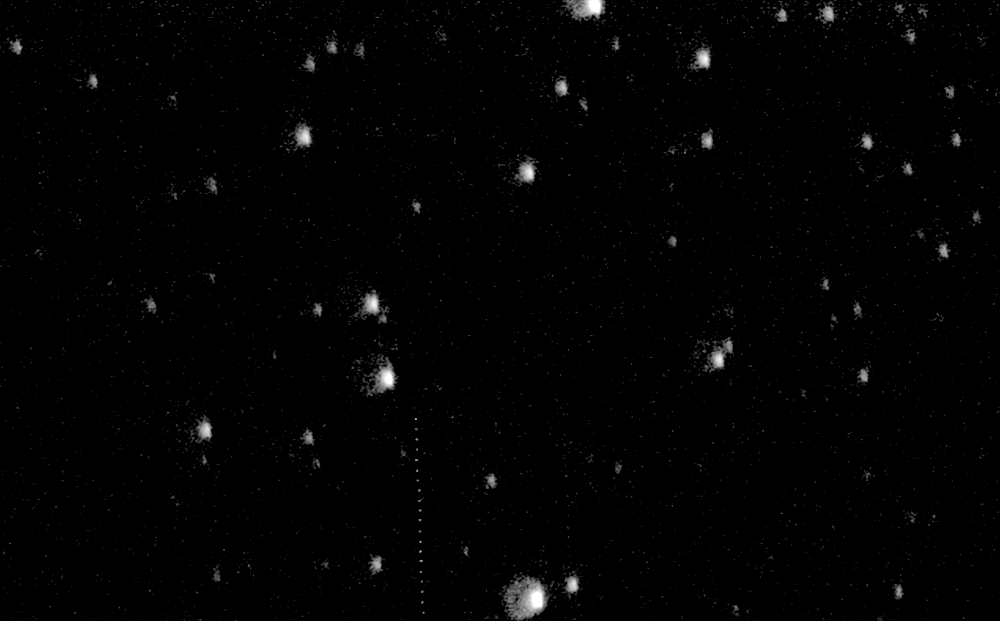

  Frame 20: sky moved 165 px since last frame

--- Reached 30 stacked frames ---
Saved & rendered: output/night_sky_30frames.png (cropped shape: (415, 538))


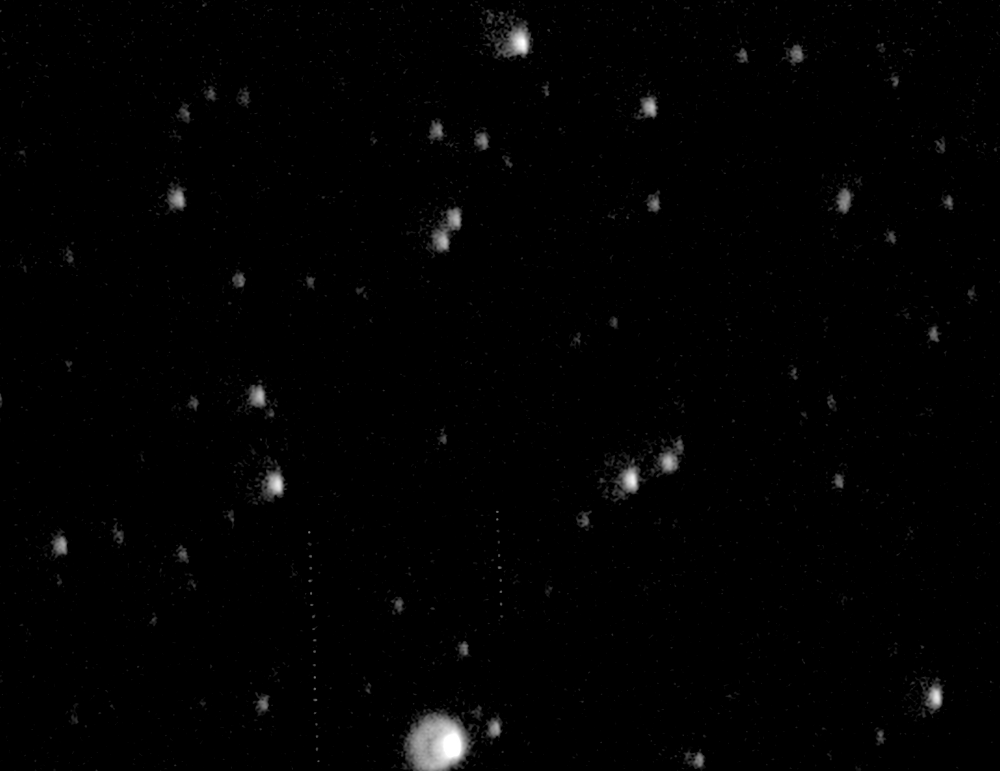


--- Reached 40 stacked frames ---
Saved & rendered: output/night_sky_40frames.png (cropped shape: (402, 537))


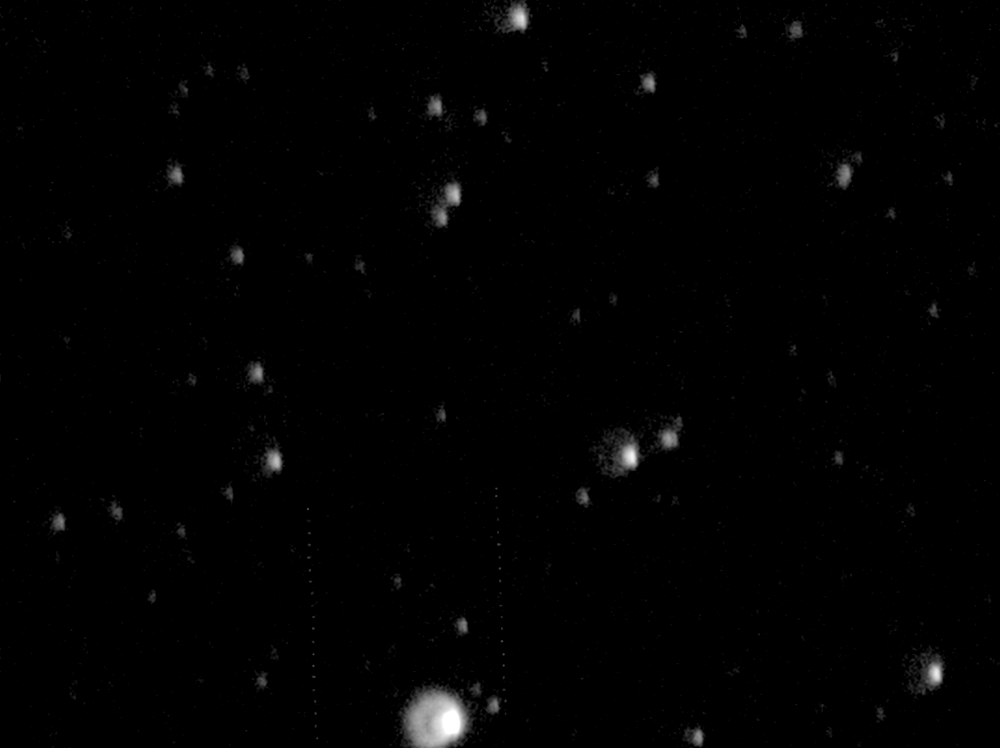

  Frame 47: sky moved 102 px since last frame

--- Reached 50 stacked frames ---
Saved & rendered: output/night_sky_50frames.png (cropped shape: (385, 535))


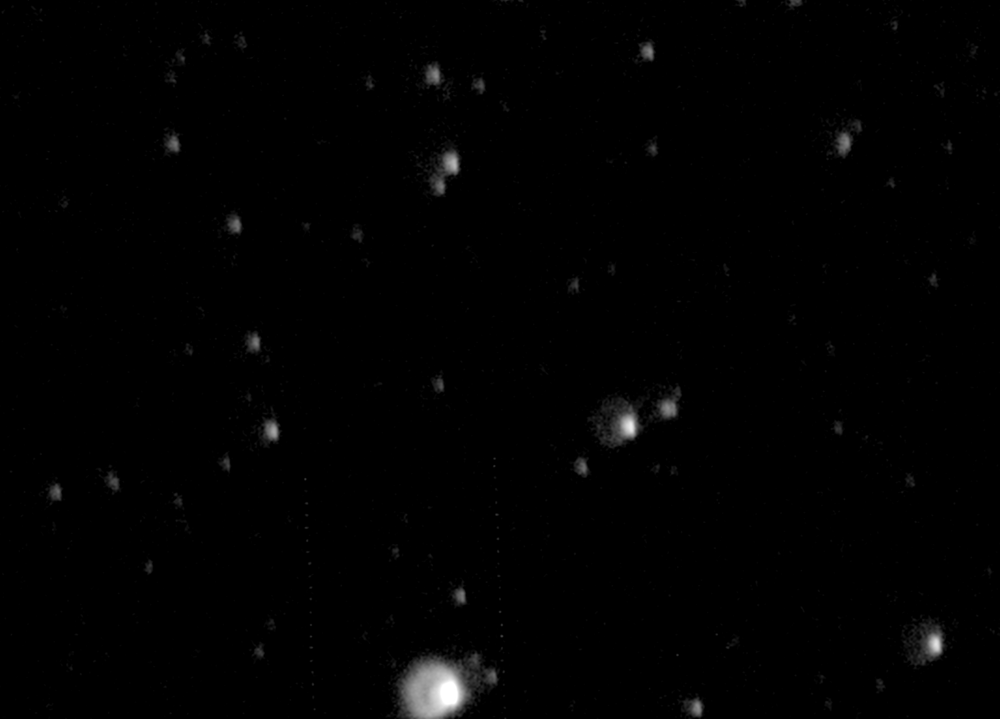

  Frame 54: sky moved 72 px since last frame
  Frame 58: sky moved 118 px since last frame
  Frame 59: sky moved 83 px since last frame

--- Reached 60 stacked frames ---
Saved & rendered: output/night_sky_60frames.png (cropped shape: (370, 533))


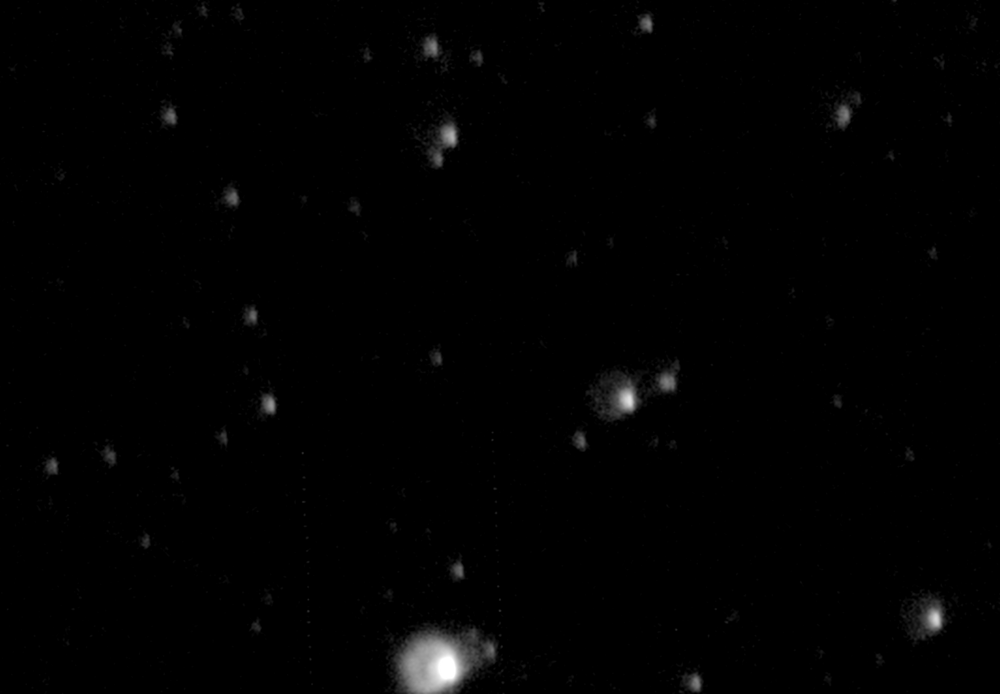

  Frame 60 skipped (low correlation: 0.016)
  Frame 61: sky moved 241 px since last frame
  Frame 62: sky moved 72 px since last frame
  Frame 70 skipped (low correlation: 0.008)
  Frame 71 skipped (low correlation: 0.012)
  Frame 72 skipped (low correlation: -0.000)
  Frame 73: sky moved 46 px since last frame
  Frame 74 skipped (low correlation: -0.010)
  Frame 75 skipped (low correlation: -0.030)
  Frame 76 skipped (low correlation: -0.014)
  Frame 77 skipped (low correlation: -0.004)
  Frame 78: sky moved 484 px since last frame

--- Reached 71 stacked frames ---
Saved & rendered: output/night_sky_71frames.png (cropped shape: (351, 524))


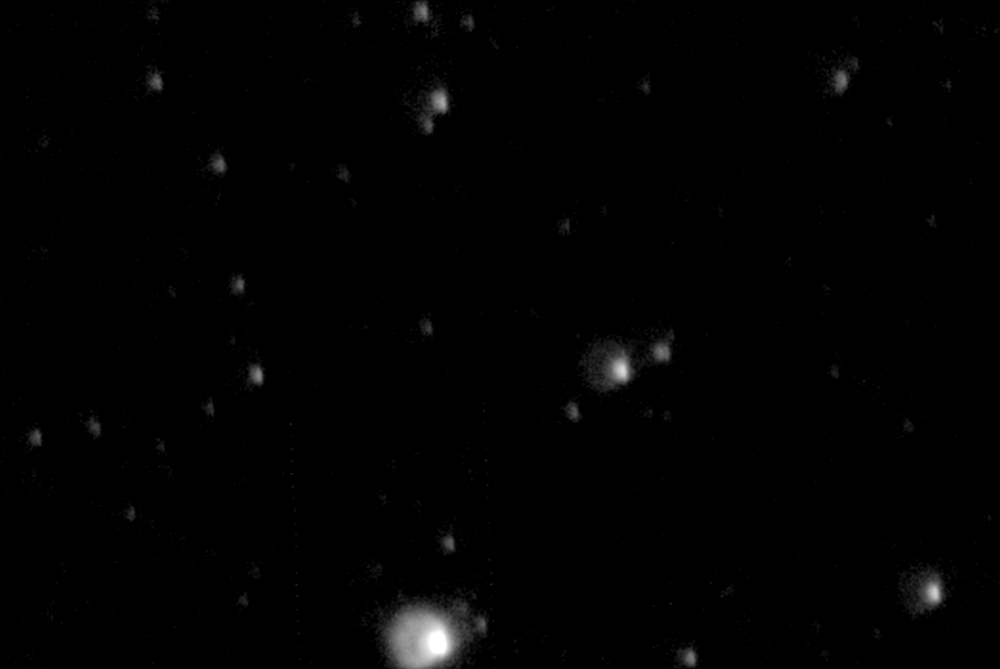

  Frame 79 skipped (low correlation: -0.024)
  Frame 80 skipped (low correlation: -0.006)
  Frame 81 skipped (low correlation: 0.000)
  Frame 82 skipped (low correlation: -0.031)
  Frame 83 skipped (low correlation: 0.011)
  Frame 84 skipped (low correlation: -0.011)
  Frame 85 skipped (low correlation: -0.017)
  Frame 86 skipped (low correlation: 0.000)
  Frame 87 skipped (low correlation: -0.001)
  Frame 88 skipped (low correlation: -0.004)
  Frame 89 skipped (low correlation: -0.001)
  Frame 90 skipped (low correlation: -0.024)
  Frame 91 skipped (low correlation: -0.029)
  Frame 92 skipped (low correlation: -0.006)
  Frame 93 skipped (low correlation: 0.009)
  Frame 94 skipped (low correlation: -0.003)
  Frame 95 skipped (low correlation: 0.000)
  Frame 96 skipped (low correlation: 0.010)
  Frame 97 skipped (low correlation: 0.003)
  Frame 98 skipped (low correlation: 0.011)
  Frame 99 skipped (low correlation: 0.003)

Complete! Stacked 71/100 frames (29 skipped).


In [19]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.stats import SigmaClip, sigma_clipped_stats
from astropy.visualization import ManualInterval, AsinhStretch, ImageNormalize
from photutils.background import Background2D, MedianBackground
from scipy.ndimage import gaussian_filter, shift as nd_shift, zoom
from skimage.registration import phase_cross_correlation
from IPython.display import Image, display

# ============================= CONFIG =======================================
LIGHTS_GLOB = "data/lights/*.fit*"
DARKS_GLOB = "data/darks/*.fit*"   # Skips automatically if empty
OUT_DIR = "output"

TARGET_COUNTS = [1, 5, 10, 20, 30, 40, 50, 60, 71]

BAYER_RGGB = False        # True: extract green channel (halves resolution) | False: mono/already debayered
ALIGN_INTEGER = False     # False: sub-pixel alignment for sharper stars | True: whole-pixel shifts
ALIGN_MODE = "stars"      # "stars": sharp stars | "blobs": out-of-focus donuts
ALIGN_SETTINGS = {"stars": (1.2, 8.0), "blobs": (4.0, 60.0)}
JUMP_WARN = 40            # Warn if scope jumps > 40 px between frames
MIN_NCC = 0.03            # Minimum correlation required to accept a frame
# ============================================================================

def load_frame(path):
    d = fits.getdata(path).astype(np.float32)
    if d.ndim == 3:
        d = d[0]
    if BAYER_RGGB:
        g1, g2 = d[0::2, 1::2], d[1::2, 0::2]
        h, w = min(g1.shape[0], g2.shape[0]), min(g1.shape[1], g2.shape[1])
        d = 0.5 * (g1[:h, :w] + g2[:h, :w])
    return d

def master_dark(shape):
    files = sorted(glob.glob(DARKS_GLOB)) if DARKS_GLOB else []
    if not files:
        print("No darks found -> skipping dark subtraction.")
        return np.zeros(shape, np.float32)
    print(f"Using {len(files)} dark frames.")
    return np.median([load_frame(f) for f in files], axis=0)

def prep_for_align(img):
    smooth, bg = ALIGN_SETTINGS[ALIGN_MODE]
    return gaussian_filter(img - gaussian_filter(img, bg), smooth)

def overlap_ncc(ref, mov, shift):
    mv = nd_shift(mov, np.round(shift), order=0, mode="constant", cval=np.nan)
    m = np.isfinite(mv)
    if m.sum() < 1000:
        return 0.0
    return float(np.corrcoef(ref[m], mv[m])[0, 1])

def render_clean_png(raw_stack, cnt_map, n_frames, out_dir):
    # 1. Bounding-box crop around pixels covered by >= 70% of frames (safe against drift)
    max_cov = cnt_map.max()
    good_cov = cnt_map >= max(1, 0.70 * max_cov)
    ys, xs = np.where(good_cov)

    if len(ys) == 0 or len(xs) == 0:
        ys, xs = np.where(cnt_map > 0)

    y0, y1 = ys.min(), ys.max() + 1
    x0, x1 = xs.min(), xs.max() + 1

    data = raw_stack[y0:y1, x0:x1].copy()
    sub_cnt = cnt_map[y0:y1, x0:x1]

    # Fill any tiny zero-coverage corner triangles with the median sky value
    valid_px = sub_cnt > 0
    if not np.all(valid_px):
        data[~valid_px] = np.median(data[valid_px])

    # Ensure box_size never exceeds cropped image dimensions
    box_h = min(32, max(8, data.shape[0] // 8))
    box_w = min(32, max(8, data.shape[1] // 8))

    # 2. Subtract uneven sky glow
    bkg = Background2D(
        data,
        box_size=(box_h, box_w),
        filter_size=(3, 3),
        sigma_clip=SigmaClip(sigma=3.0),
        bkg_estimator=MedianBackground(),
        coverage_mask=~valid_px,
    )
    sub = data - bkg.background

    # 3. Scale noise suppression and sharpening based on frame count 'n_frames'
    if n_frames < 10:
        sharpen_amount = 0.15
        sigma_clip_mult = 3.2   # Push single-frame noise below pure black
        asinh_a = 0.15          # Gentler stretch so noise doesn't pop
    else:
        sharpen_amount = 0.45
        sigma_clip_mult = 1.8
        asinh_a = 0.04

    # 4. 3x bicubic upscale + adaptive unsharp mask
    upscaled = zoom(sub, zoom=3.0, order=3)
    blurred = gaussian_filter(upscaled, sigma=2.2)
    sharpened = upscaled + sharpen_amount * (upscaled - blurred)
    final_sky = gaussian_filter(sharpened, sigma=0.7)

    # 5. Pure black night sky stretch
    _, median, std = sigma_clipped_stats(final_sky, sigma=3.0)
    vmin = median + sigma_clip_mult * std
    vmax = np.percentile(final_sky, 99.96)
    norm = ImageNormalize(
        final_sky,
        interval=ManualInterval(vmin=vmin, vmax=vmax),
        stretch=AsinhStretch(a=asinh_a),
    )

    # 6. Save & display PNG
    fig, ax = plt.subplots(figsize=(10, 8.4), dpi=300)
    fig.patch.set_facecolor("black")
    ax.set_facecolor("black")
    ax.imshow(final_sky, origin="lower", cmap="gray", norm=norm, interpolation="lanczos")
    ax.axis("off")

    clean_png = f"{out_dir}/night_sky_{n_frames:02d}frames.png"
    plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
    plt.savefig(clean_png, facecolor="black", dpi=300, bbox_inches="tight", pad_inches=0)
    plt.close(fig)
    print(f"Saved & rendered: {clean_png} (cropped shape: {data.shape})")
    display(Image(filename=clean_png))

def run_pipeline():
    os.makedirs(OUT_DIR, exist_ok=True)
    for old in glob.glob(f"{OUT_DIR}/stack_*.fits"):
        os.remove(old)

    files = sorted(glob.glob(LIGHTS_GLOB))
    if not files:
        raise FileNotFoundError(f"No light frames found matching {LIGHTS_GLOB}")
    print(f"Found {len(files)} light frames.")

    first = load_frame(files[0])
    dark = master_dark(first.shape)
    ref = first - dark

    acc = np.zeros(ref.shape, np.float64)
    cnt = np.zeros(ref.shape, np.float64)
    ref_prep = prep_for_align(ref)
    last_total = np.zeros(2)
    ncc_hist = []
    n_ok, skipped = 0, 0

    checkpoints = set(n for n in TARGET_COUNTS if n <= len(files))

    for i, f in enumerate(files):
        img = load_frame(f) - dark
        if i == 0:
            aligned, valid = img, np.ones(img.shape, bool)
        else:
            cur = prep_for_align(img)
            total, _, _ = phase_cross_correlation(ref_prep, cur, upsample_factor=20, normalization=None)
            q = overlap_ncc(ref_prep, cur, total)
            floor = max(MIN_NCC, 0.3 * np.median(ncc_hist)) if len(ncc_hist) >= 5 else MIN_NCC
            if q < floor:
                skipped += 1
                print(f"  Frame {i} skipped (low correlation: {q:.3f})")
                continue
            ncc_hist.append(q)

            step = float(np.hypot(*(total - last_total)))
            if step > JUMP_WARN:
                print(f"  Frame {i}: sky moved {step:.0f} px since last frame")
            last_total = total.copy()

            sh = np.round(total) if ALIGN_INTEGER else total
            order = 0 if ALIGN_INTEGER else 1
            aligned = nd_shift(img, sh, order=order, mode="constant", cval=0.0)
            valid = nd_shift(np.ones(img.shape), sh, order=order, mode="constant", cval=0.0) > 0.999

        acc += aligned * valid
        cnt += valid
        n_ok += 1

        # Refresh alignment reference every 4 frames
        if n_ok % 4 == 0:
            mean_ref = acc / np.maximum(cnt, 1)
            covered = cnt > 0
            mean_ref[~covered] = np.median(mean_ref[covered])
            ref_prep = prep_for_align(mean_ref.astype(np.float32))

        # Save FITS & render clean PNG at each target frame count
        if n_ok in checkpoints:
            print(f"\n--- Reached {n_ok} stacked frames ---")
            mean_stack = np.where(cnt > 0, acc / np.maximum(cnt, 1), 0).astype(np.float32)
            hdu = fits.PrimaryHDU(mean_stack)
            hdu.header["NFRAMES"] = n_ok
            fits_path = f"{OUT_DIR}/stack_{n_ok:04d}.fits"
            hdu.writeto(fits_path, overwrite=True)

            render_clean_png(mean_stack, cnt, n_ok, OUT_DIR)

    print(f"\nComplete! Stacked {n_ok}/{len(files)} frames ({skipped} skipped).")

run_pipeline()


Deepest stack N=71: FWHM=6.0 px -> aperture=6.0 px, annulus=9.6-14.4 px
Total clean stars detected: 62 (0 saturated)
4 Dimmest Chosen Star IDs: [58 59 60 62] (Deepest SNRs: [7.13 7.1  6.24 5.23])
  -> Star ID 58: (x=492.8, y=240.2), Deepest SNR=7.13
  -> Star ID 59: (x=563.1, y=339.4), Deepest SNR=7.10
  -> Star ID 60: (x=494.8, y=433.6), Deepest SNR=6.24
  -> Star ID 62: (x=591.0, y=181.0), Deepest SNR=5.23


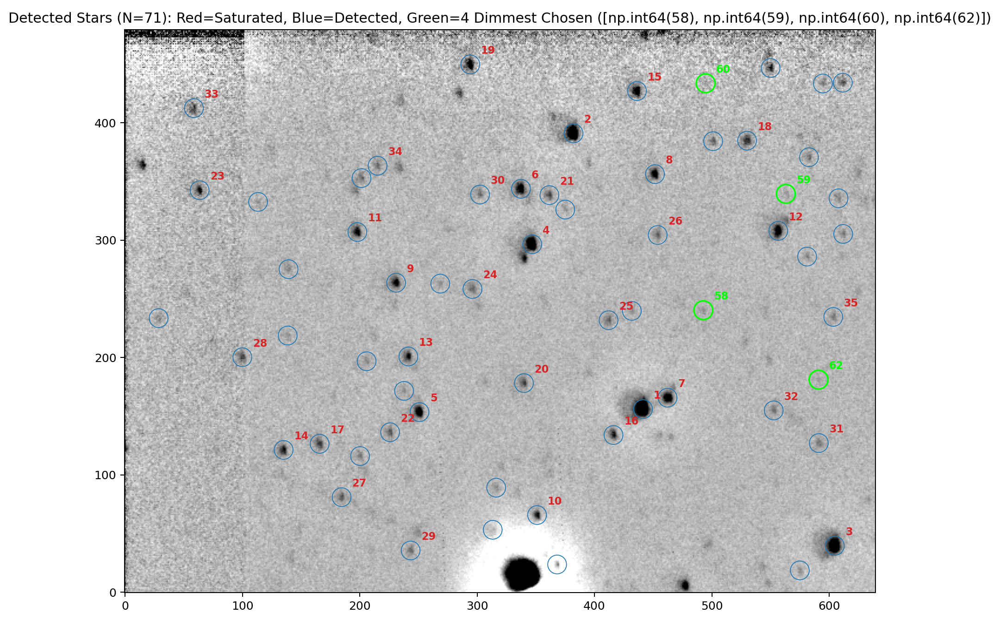

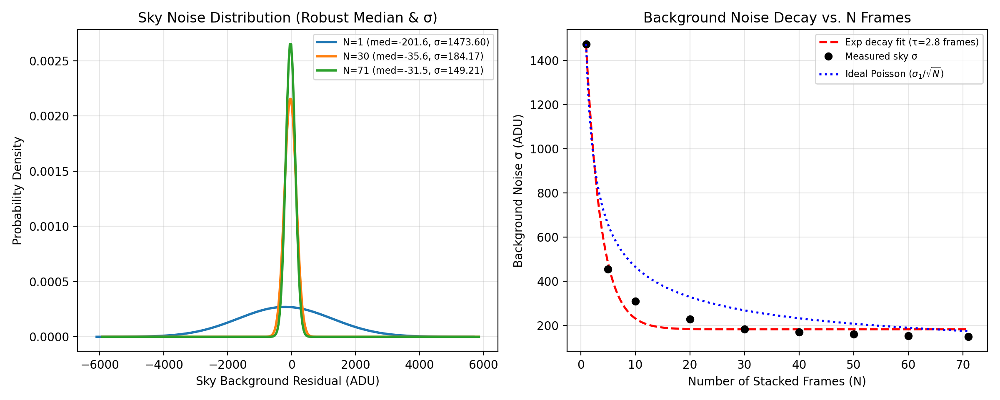

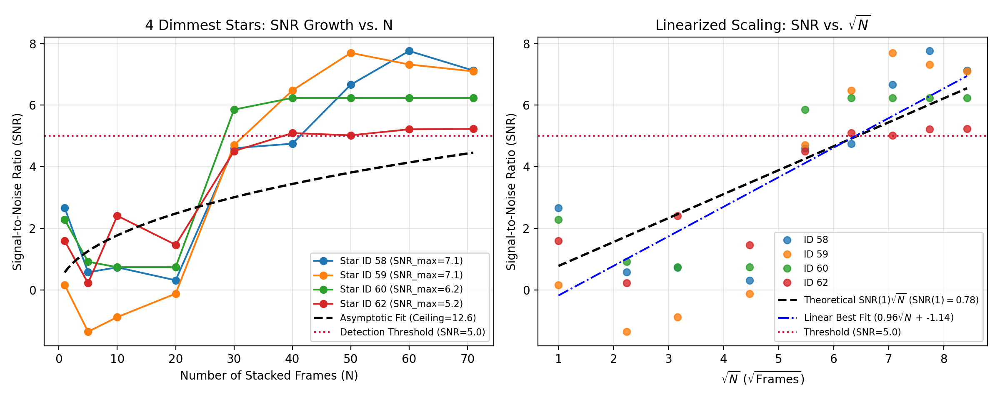


Calibration Zero-Point: ZP = 16.31 mag (Scatter = 1.01 mag)

--- Calibrated True Brightness of the 4 Dimmest Chosen Stars ---
Star ID 58: True Brightness V = 14.17 mag (Deepest SNR = 7.13)
Star ID 59: True Brightness V = 14.18 mag (Deepest SNR = 7.10)
Star ID 60: True Brightness V = 14.32 mag (Deepest SNR = 6.24)
Star ID 62: True Brightness V = 14.51 mag (Deepest SNR = 5.23)

  N   | Faintest Star Detected (V) | Theoretical m_lim (V)
------+----------------------------+----------------------
 1    |            12.62           |          9.20
 5    |            14.14           |          9.67
 10   |            14.14           |         10.21
 20   |            14.14           |          7.17
 30   |            14.32           |         14.34
 40   |            14.51           |         14.50
 50   |            14.51           |         14.63
 60   |            14.51           |         14.59
 71   |            14.51           |         14.56


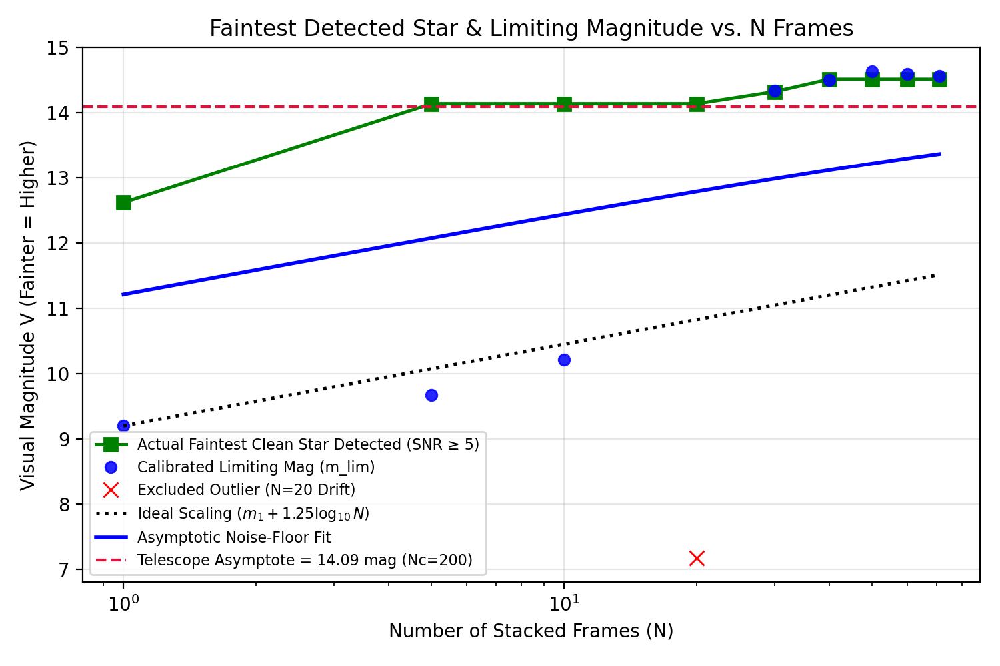


Saved clean results tables to output/results_table.xlsx and CSVs!


In [1]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.stats import SigmaClip, sigma_clipped_stats
from photutils.aperture import CircularAperture, CircularAnnulus, ApertureStats
from photutils.detection import DAOStarFinder
from scipy.ndimage import gaussian_filter, binary_erosion, maximum_filter
from scipy.optimize import curve_fit
from scipy.spatial import cKDTree
from IPython.display import Image, display

# ============================= CONFIG =======================================
OUT_DIR = "output"
os.makedirs(OUT_DIR, exist_ok=True)

SAT_LEVEL = 65535
DETECT_SIGMA = 4.0       # Systematic source detection threshold (3.0 or 4.0 sigma)
SNR_LIMIT = 5.0          # Detection threshold defining limiting magnitude
CAL_MIN_SNR = 8.0        # Minimum SNR on deepest stack for calibration stars

# Map your identified Tycho-2 stars (V-band magnitudes) to the IDs shown in star_map.png:
CALIB_STARS = {
    # star_id: V_mag
    1: 8.61,   # TYC 1859-1083-1 / HD 35348 (V = 8.61)
    2: 10.81,  # TYC 4859-502-1 (V = 10.81)
    3: 11.40,  # TYC 1859-1188-1 (V = 11.40)
    4: 11.43,  # TYC 1859-585-1 (V = 11.43)
    5: 11.82,  # TYC 1859-1430-1 (V = 11.82)
}
# ============================================================================

def snr_model(N, A, Nc):
    """SNR(N) = A * sqrt(N) / sqrt(1 + N / Nc): grows as sqrt(N), then plateaus at ceiling."""
    return A * np.sqrt(N) / np.sqrt(1 + N / Nc)

def fit_snr_model(N, y, max_nc=5000.0):
    N, y = np.asarray(N, float), np.asarray(y, float)
    g = np.isfinite(y) & (y > 0)
    if g.sum() < 4:
        return None
    N, y = N[g], y[g]
    f = lambda n, lA, lNc: np.log(snr_model(n, np.exp(lA), np.exp(lNc)))
    try:
        p, _ = curve_fit(
            f, N, np.log(y),
            p0=[np.log(y[0]), np.log(N.max() * 1.5)],
            bounds=([-20, 0], [20, np.log(max_nc)])
        )
        return float(np.exp(p[0])), float(np.exp(p[1]))
    except Exception:
        return None

def estimate_fwhm(img, n_stars=8):
    hp = img - gaussian_filter(img, 30)
    sm = gaussian_filter(hp, 2)
    peaks = (sm == maximum_filter(sm, 25)) & (sm > np.percentile(sm, 99.8))
    out = []
    for y, x in zip(*np.nonzero(peaks)):
        if y < 40 or x < 40 or y > img.shape[0] - 40 or x > img.shape[1] - 40:
            continue
        cut = hp[y - 30:y + 31, x - 30:x + 31]
        yy, xx = np.mgrid[-30:31, -30:31]
        r = np.hypot(xx, yy)
        prof = np.array([np.median(cut[(r >= k) & (r < k + 1)]) for k in range(25)])
        peak = gaussian_filter(cut, 1)[28:33, 28:33].max()
        out.append((peak, 2.0 * int(np.argmax(prof < peak / 2))))
    out.sort(key=lambda t: -t[0])
    return float(np.median([w for _, w in out[:n_stars]])) if out else 2.5

def measure_photometry(data, xy, aper_r, ann_in, ann_out):
    ap = CircularAperture(xy, r=aper_r)
    an = CircularAnnulus(xy, r_in=ann_in, r_out=ann_out)
    a = ApertureStats(data, ap)
    s = ApertureStats(data, an, sigma_clip=SigmaClip(3.0, maxiters=5))
    n_pix, n_sky = ap.area, an.area
    flux = a.sum - n_pix * s.median
    noise = s.std * np.sqrt(n_pix * (1 + n_pix / n_sky))
    return flux, noise, a.max, s.median, s.std

def run_analysis():
    # 1. Load saved stacks
    stack_files = sorted(glob.glob(f"{OUT_DIR}/stack_*.fits"))
    if not stack_files:
        raise FileNotFoundError(f"No stack_*.fits found in {OUT_DIR}/")

    stacks = []
    for f in stack_files:
        with fits.open(f) as h:
            stacks.append((int(h[0].header["NFRAMES"]), h[0].data.astype(np.float64)))
    stacks.sort(key=lambda t: t[0])

    Ns = np.array([n for n, _ in stacks], dtype=float)
    deep_N, deep = stacks[-1]

    # Build valid interior overlap mask (ignores external/drifted zero edges)
    overlap_mask = np.ones_like(deep, dtype=bool)
    for _, img in stacks:
        overlap_mask &= (img > 0)

    w = estimate_fwhm(deep)
    fwhm = max(2.0, w)
    aper_r = fwhm
    ann_in = max(aper_r + 2.0, 1.6 * fwhm)
    ann_out = max(ann_in + 3.0, 2.4 * fwhm)
    iso_radius = max(4.0, 1.6 * fwhm)
    valid = binary_erosion(overlap_mask, iterations=int(ann_out) + 2)
    print(f"Deepest stack N={int(deep_N)}: FWHM={fwhm:.1f} px -> aperture={aper_r:.1f} px, annulus={ann_in:.1f}-{ann_out:.1f} px")

    # 2. Systematic Source Finding via DAOStarFinder (> DETECT_SIGMA)
    hp_deep = deep - gaussian_filter(deep, max(25, 3 * fwhm))
    _, med_sky, std_sky = sigma_clipped_stats(hp_deep[valid], sigma=3.0)
    finder = DAOStarFinder(fwhm=fwhm, threshold=DETECT_SIGMA * std_sky)
    sources = finder(hp_deep - med_sky)
    if sources is None or len(sources) == 0:
        raise RuntimeError("No stars found. Try lowering DETECT_SIGMA to 3.0.")

    xc = "x_centroid" if "x_centroid" in sources.colnames else "xcentroid"
    yc = "y_centroid" if "y_centroid" in sources.colnames else "ycentroid"
    x, y = np.array(sources[xc]), np.array(sources[yc])

    # Keep only interior stars with no crowded neighbors
    in_bounds = valid[np.round(y).astype(int), np.round(x).astype(int)]
    x, y = x[in_bounds], y[in_bounds]
    tree = cKDTree(np.c_[x, y])
    isolated = np.array([len(nb) == 1 for nb in tree.query_ball_point(np.c_[x, y], iso_radius)])
    x, y = x[isolated], y[isolated]
    xy = np.c_[x, y]

    # 3. Measure Flux, Noise, and SNR across all N stacks
    snr_mat = np.zeros((len(stacks), len(x)))
    sky_stds = np.zeros(len(stacks))
    sky_meds = np.zeros(len(stacks))
    deep_peak = np.zeros(len(x))

    for k, (n, data) in enumerate(stacks):
        flux, noise, peak, _, _ = measure_photometry(data, xy, aper_r, ann_in, ann_out)
        snr_mat[k] = flux / noise
        if n == deep_N:
            deep_peak = peak
        hp_k = data - gaussian_filter(data, max(25, 3 * fwhm))
        _, m_k, s_k = sigma_clipped_stats(hp_k[valid], sigma=3.0)
        sky_meds[k] = m_k
        sky_stds[k] = s_k

    # Filter to stars cleanly detected on deepest stack and sort brightest -> dimmest
    keep = snr_mat[-1] >= SNR_LIMIT
    x, y, snr_mat, deep_peak = x[keep], y[keep], snr_mat[:, keep], deep_peak[keep]
    order = np.argsort(-snr_mat[-1])
    x, y, snr_mat, deep_peak = x[order], y[order], snr_mat[:, order], deep_peak[order]
    sat = (deep_peak > 0.9 * SAT_LEVEL)
    ids = np.arange(1, len(x) + 1)

    # Filter out hot-pixel/cosmic-ray spikes BEFORE plotting star_map.png
    unsat_idx = np.where(~sat)[0]
    clean_unsat = [i for i in unsat_idx if snr_mat[-1, i] >= np.max(snr_mat[:, i]) * 0.75]
    dim4_idx = clean_unsat[-4:] if len(clean_unsat) >= 4 else unsat_idx[-4:]

    print(f"Total clean stars detected: {len(x)} ({sat.sum()} saturated)")
    print(f"4 Dimmest Chosen Star IDs: {ids[dim4_idx]} (Deepest SNRs: {np.round(snr_mat[-1, dim4_idx], 2)})")
    for idx_s in dim4_idx:
        print(f"  -> Star ID {ids[idx_s]}: (x={x[idx_s]:.1f}, y={y[idx_s]:.1f}), Deepest SNR={snr_mat[-1, idx_s]:.2f}")

    # 4. Save Labelled Star Map (Now highlights IDs 58, 59, 60, 62 in green!)
    disp_img = np.clip(hp_deep - med_sky, *np.percentile(hp_deep[valid] - med_sky, [1, 99.7]))
    fig, ax = plt.subplots(figsize=(12, 7.5))
    ax.imshow(disp_img, cmap="gray_r", origin="lower")
    for i in range(len(x)):
        is_dim4 = i in dim4_idx
        color = "lime" if is_dim4 else ("red" if sat[i] else "tab:blue")
        ax.add_patch(plt.Circle((x[i], y[i]), 8, fill=False, color=color, lw=1.4 if is_dim4 else 0.7))
        if i < 35 or is_dim4:
            ax.text(x[i] + 9, y[i] + 9, str(ids[i]), color="lime" if is_dim4 else "tab:red", fontsize=9, fontweight="bold")
    ax.set_title(f"Detected Stars (N={int(deep_N)}): Red=Saturated, Blue=Detected, Green=4 Dimmest Chosen ({list(ids[dim4_idx])})")
    fig.tight_layout()
    map_png = f"{OUT_DIR}/star_map.png"
    fig.savefig(map_png, dpi=180)
    plt.close(fig)
    display(Image(filename=map_png))

    # 5. PLOT A: Robust Sky Noise Gaussian Wave & Exponential/Power-Law Decay vs N
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

    for k in [0, len(stacks) // 2, -1]:
        n_val, data_k = stacks[k]
        hp_k = data_k - gaussian_filter(data_k, max(25, 3 * fwhm))
        _, mu, sig = sigma_clipped_stats(hp_k[valid], sigma=3.0)
        xg = np.linspace(mu - 4 * sky_stds[0], mu + 4 * sky_stds[0], 300)
        gauss_pdf = (1.0 / (sig * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((xg - mu) / sig) ** 2)
        ax1.plot(xg, gauss_pdf, lw=2, label=f"N={int(n_val)} (med={mu:.1f}, σ={sig:.2f})")
    ax1.set_xlabel("Sky Background Residual (ADU)")
    ax1.set_ylabel("Probability Density")
    ax1.set_title("Sky Noise Distribution (Robust Median & σ)")
    ax1.legend(fontsize=8)
    ax1.grid(alpha=0.3)

    n_smooth = np.linspace(Ns.min(), Ns.max(), 200)
    ideal_noise = sky_stds[0] / np.sqrt(n_smooth / Ns[0])
    try:
        popt_exp, _ = curve_fit(
            lambda n, a, b, c: a * np.exp(-b * n) + c, Ns, sky_stds,
            p0=[sky_stds[0], 0.05, sky_stds[-1]], maxfev=5000
        )
        ax2.plot(
            n_smooth, popt_exp[0] * np.exp(-popt_exp[1] * n_smooth) + popt_exp[2],
            "r--", lw=1.8, label=f"Exp decay fit (τ={1 / popt_exp[1]:.1f} frames)"
        )
    except Exception:
        pass
    ax2.plot(Ns, sky_stds, "ko", markersize=6, label="Measured sky σ")
    ax2.plot(n_smooth, ideal_noise, "b:", lw=1.8, label=r"Ideal Poisson ($\sigma_1 / \sqrt{N}$)")
    ax2.set_xlabel("Number of Stacked Frames (N)")
    ax2.set_ylabel("Background Noise σ (ADU)")
    ax2.set_title("Background Noise Decay vs. N Frames")
    ax2.legend(fontsize=8)
    ax2.grid(alpha=0.3)

    fig.tight_layout()
    noise_png = f"{OUT_DIR}/noise_decay_analysis.png"
    fig.savefig(noise_png, dpi=200)
    plt.close(fig)
    display(Image(filename=noise_png))

    # 6. PLOT B: SNR vs N & Linearized SNR vs sqrt(N) for the 4 Dimmest Clean Stars
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
    Ng = np.logspace(0, np.log10(Ns.max()), 150)

    for idx_s in dim4_idx:
        ys = snr_mat[:, idx_s]
        ax1.plot(Ns, ys, "o-", lw=1.5, label=f"Star ID {ids[idx_s]} (SNR_max={ys[-1]:.1f})")

    med_dim4 = np.median(snr_mat[:, dim4_idx], axis=1)
    ft_dim4 = fit_snr_model(Ns, med_dim4, max_nc=500.0)

    if ft_dim4:
        snr_ceil = ft_dim4[0] * np.sqrt(ft_dim4[1])
        ax1.plot(Ng, snr_model(Ng, *ft_dim4), "k--", lw=2, label=f"Asymptotic Fit (Ceiling={snr_ceil:.1f})")

    ax1.axhline(SNR_LIMIT, color="crimson", ls=":", lw=1.5, label=f"Detection Threshold (SNR={SNR_LIMIT})")
    ax1.set_xlabel("Number of Stacked Frames (N)")
    ax1.set_ylabel("Signal-to-Noise Ratio (SNR)")
    ax1.set_title("4 Dimmest Stars: SNR Growth vs. N")
    ax1.legend(fontsize=8)
    ax1.grid(alpha=0.3)

    sqrt_N = np.sqrt(Ns)
    for idx_s in dim4_idx:
        ax2.plot(sqrt_N, snr_mat[:, idx_s], "o", alpha=0.8, label=f"ID {ids[idx_s]}")

    snr1_fit = np.sum(sqrt_N * med_dim4) / np.sum(sqrt_N ** 2)
    slope, intercept = np.polyfit(sqrt_N, med_dim4, 1)

    ax2.plot(
        sqrt_N, snr1_fit * sqrt_N, "k--", lw=2,
        label=rf"Theoretical $\mathrm{{SNR}}(1)\sqrt{{N}}$ ($\mathrm{{SNR}}(1)={snr1_fit:.2f}$)"
    )
    ax2.plot(
        sqrt_N, slope * sqrt_N + intercept, "b-.", lw=1.5,
        label=rf"Linear Best Fit ({slope:.2f}$\sqrt{{N}}$ + {intercept:.2f})"
    )
    ax2.axhline(SNR_LIMIT, color="crimson", ls=":", lw=1.5, label=f"Threshold (SNR={SNR_LIMIT})")
    ax2.set_xlabel(r"$\sqrt{N}$ ($\sqrt{\mathrm{Frames}}$)")
    ax2.set_ylabel("Signal-to-Noise Ratio (SNR)")
    ax2.set_title(r"Linearized Scaling: SNR vs. $\sqrt{N}$")
    ax2.legend(fontsize=8)
    ax2.grid(alpha=0.3)

    fig.tight_layout()
    snr_png = f"{OUT_DIR}/snr_scaling_4dimmest.png"
    fig.savefig(snr_png, dpi=200)
    plt.close(fig)
    display(Image(filename=snr_png))

    # 7. PLOT C: Limiting Magnitude vs N & Asymptotic Telescope Detection Threshold
    # 7. PLOT C: True Magnitudes of 4 Dimmest Stars + Faintest Detected Star vs. N
    valid_cal = [
        (sid - 1, mag) for sid, mag in CALIB_STARS.items()
        if 1 <= sid <= len(ids) and not sat[sid - 1] and snr_mat[-1, sid - 1] >= CAL_MIN_SNR
    ]

    if len(valid_cal) < 3:
        print(f"\n[Calibration Paused] Found {len(valid_cal)} usable stars in CALIB_STARS.")
        return

    ks = np.array([k for k, _ in valid_cal])
    mags = np.array([m for _, m in valid_cal])

    # Compute photometric zero-point from the deepest stack (N=71)
    zp_vals = mags + 2.5 * np.log10(snr_mat[-1, ks])
    zp_med = np.median(zp_vals)
    print(f"\nCalibration Zero-Point: ZP = {zp_med:.2f} mag (Scatter = {np.std(zp_vals):.2f} mag)")

    # 1) Calculate TRUE calibrated visual magnitude (V) for all detected stars
    star_mags_V = zp_med - 2.5 * np.log10(np.maximum(snr_mat[-1], 1e-6))

    print("\n--- Calibrated True Brightness of the 4 Dimmest Chosen Stars ---")
    for idx_s in dim4_idx:
        print(f"Star ID {ids[idx_s]}: True Brightness V = {star_mags_V[idx_s]:.2f} mag (Deepest SNR = {snr_mat[-1, idx_s]:.2f})")

    # 2) Find the ACTUAL faintest clean star detected (SNR >= 5) at each stack size N
    faintest_detected_mag = np.full(len(Ns), np.nan)
    for j in range(len(Ns)):
        detected_j = [i for i in clean_unsat if snr_mat[j, i] >= SNR_LIMIT]
        if len(detected_j) > 0:
            faintest_detected_mag[j] = np.max(star_mags_V[detected_j])

    # 3) Theoretical limiting magnitude curve from calibration constant C
    C = np.array([np.median(snr_mat[j, ks] * 10 ** (0.4 * mags)) for j in range(len(Ns))])
    mlim = 2.5 * np.log10(C / SNR_LIMIT)
    ideal_mlim = mlim[0] + 1.25 * np.log10(Ns / Ns[0])

    print("\n  N   | Faintest Star Detected (V) | Theoretical m_lim (V)")
    print("------+----------------------------+----------------------")
    for n, fd, m in zip(Ns, faintest_detected_mag, mlim):
        print(f" {int(n):<4d} |           {fd:6.2f}           |        {m:6.2f}")

    # Exclude the N=20 outlier dip when fitting the asymptotic ceiling
    valid_fit = (mlim >= mlim[0] - 0.5) & np.isfinite(C) & (C > 0)
    fit_c = fit_snr_model(Ns[valid_fit], C[valid_fit], max_nc=200.0)

    fig, ax = plt.subplots(figsize=(7.5, 5))
    ax.semilogx(Ns, faintest_detected_mag, "gs-", markersize=7, lw=1.8, label="Actual Faintest Clean Star Detected (SNR ≥ 5)")
    ax.semilogx(Ns[valid_fit], mlim[valid_fit], "bo", markersize=6, alpha=0.85, label="Calibrated Limiting Mag (m_lim)")
    if (~valid_fit).any():
        ax.semilogx(Ns[~valid_fit], mlim[~valid_fit], "rx", markersize=8, lw=2, label="Excluded Outlier (N=20 Drift)")
    ax.semilogx(Ns, ideal_mlim, "k:", lw=1.8, label=r"Ideal Scaling ($m_1 + 1.25 \log_{10} N$)")

    if fit_c:
        A, Nc = fit_c
        m_inf = 2.5 * np.log10(A * np.sqrt(Nc) / SNR_LIMIT)
        ax.semilogx(Ng, 2.5 * np.log10(snr_model(Ng, *fit_c) / SNR_LIMIT), "b-", lw=2, label="Asymptotic Noise-Floor Fit")
        ax.axhline(m_inf, color="crimson", ls="--", lw=1.5, label=f"Telescope Asymptote = {m_inf:.2f} mag (Nc={Nc:.0f})")

    ax.set_xlabel("Number of Stacked Frames (N)")
    ax.set_ylabel("Visual Magnitude V (Fainter = Higher)")
    ax.set_title("Faintest Detected Star & Limiting Magnitude vs. N Frames")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    mlim_png = f"{OUT_DIR}/limiting_magnitude_vs_N.png"
    fig.savefig(mlim_png, dpi=200)
    plt.close(fig)
    display(Image(filename=mlim_png))
    # 8. EXPORT CLEAN RESULTS TABLES (CSV & EXCEL)
    import pandas as pd

    # Table 1: Limiting Magnitude & Sky Noise vs. N Frames
    df_scaling = pd.DataFrame({
        "N_Frames": Ns.astype(int),
        "Sky_Noise_Sigma_ADU": np.round(sky_stds, 2),
        "Faintest_Star_Detected_V": np.round(faintest_detected_mag, 2),
        "Theoretical_mlim_V": np.round(mlim, 2),
        "Ideal_mlim_V": np.round(ideal_mlim, 2),
    })

    # Table 2: Calibrated Properties of the 4 Dimmest Chosen Stars
    df_dim4 = pd.DataFrame({
        "Star_ID": ids[dim4_idx],
        "X_px": np.round(x[dim4_idx], 1),
        "Y_px": np.round(y[dim4_idx], 1),
        "Deepest_SNR_N71": np.round(snr_mat[-1, dim4_idx], 2),
        "Calibrated_V_mag": np.round(star_mags_V[dim4_idx], 2),
    })

    # Save as CSVs (and a combined 2-sheet Excel workbook)
    df_scaling.to_csv(f"{OUT_DIR}/results_limiting_mag_vs_N.csv", index=False)
    df_dim4.to_csv(f"{OUT_DIR}/results_4_dimmest_stars.csv", index=False)

    with pd.ExcelWriter(f"{OUT_DIR}/results_table.xlsx") as writer:
        df_scaling.to_excel(writer, sheet_name="Limiting_Magnitude_vs_N", index=False)
        df_dim4.to_excel(writer, sheet_name="4_Dimmest_Stars", index=False)

    print(f"\nSaved clean results tables to {OUT_DIR}/results_table.xlsx and CSVs!")


run_analysis()
